# Benchmark 3: Genetic Toggle Switch

Symmetric genetic toggle switch model, two pitchfork bifurcations at $\mu_\pm = \pm 2$:
$$\dot{u} = f(u, \mu) = \begin{pmatrix} -x + \frac{\mu}{1 + y^2} \\ -y + \frac{\mu}{1 + x^2} \end{pmatrix}, \qquad u = (x, y)^\top$$

1. Double pitchfork bifurcation.
2. Uniqueness regime.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from pce_galerkin import PCEGalerkin, set_plot_style, plot_2d, plot_3d

set_plot_style(usetex=True)

def rhs(u, mu):
    x, y = u[0], u[1]
    return np.array([-x + mu / (1.0 + y**2), -y + mu / (1.0 + x**2)])

def jac(u, mu):
    x, y = u[0], u[1]
    J = np.empty((2, 2, len(mu)))
    J[0, 0] = -1.0
    J[0, 1] = -2.0 * mu * y / (1.0 + y**2)**2
    J[1, 0] = -2.0 * mu * x / (1.0 + x**2)**2
    J[1, 1] = -1.0
    return J

def exact_branches(bounds):
    mu_ex = np.linspace(bounds[0], bounds[1], 600)
    s = np.sqrt(0.25 * mu_ex**2 + 1.0 / 27.0)
    x0 = np.cbrt(0.5 * mu_ex + s) + np.cbrt(0.5 * mu_ex - s)
    curves = [(mu_ex, np.vstack([x0, x0]))]

    if np.any(np.abs(mu_ex) >= 2.0):
        disc = np.where(np.abs(mu_ex) >= 2.0, mu_ex**2 - 4.0, np.nan)
        xp = 0.5 * (mu_ex + np.sqrt(disc))
        xm = 0.5 * (mu_ex - np.sqrt(disc))
        curves += [(mu_ex, np.vstack([xp, xm])), (mu_ex, np.vstack([xm, xp]))]
    return curves

def plot_toggle(solver, branches):
    exact = exact_branches(solver.mu_bounds)
    labels = [rf"Branch {idx + 1}" for idx in range(len(branches))]
    fig = plt.figure(figsize=(12, 5))
    ax2d = fig.add_subplot(1, 2, 1)
    ax3d = fig.add_subplot(1, 2, 2, projection="3d")
    plot_2d(solver, branches, exact, state_idx=0, branch_labels=labels,
            exact_label=r"Exact $\bar{u}$", ylabel=r"$x$", ax=ax2d)
    plot_3d(solver, branches, exact, idx_pair=(0, 1), labels=(r"$x$", r"$y$"), ax=ax3d)
    plt.tight_layout()
    plt.show()

## 1. Double pitchfork bifurcation

Degree continuation to capture both the symmetric branch $\bar{u}_0$ and the asymmetric branches across two pitchfork bifurcations at $\mu_\pm = \pm 2$.

Found 3 branches on (-5.0, 16.0)


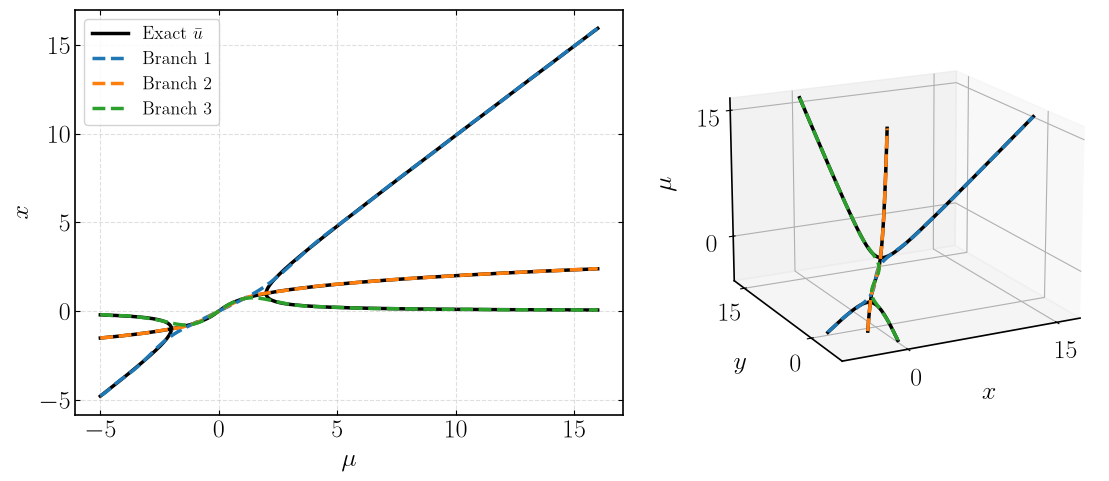

In [2]:
bounds = (-5.0, 16.0)
N = 20
solver = PCEGalerkin(rhs, jac, mu_bounds=bounds, state_dim=2, quad_order=100)
branches = solver.find_branches(N, n_samples=100, seed=42, unique_tol=1e-2,
                                box=(-3.0, 3.0), start_degree=0, res_tol=None)
print(f"Found {len(branches)} branches on {bounds}")
plot_toggle(solver, branches)

## 2. Uniqueness regime

On $I = [-2, 2]$, only the symmetric branch $\bar{u}_0(\mu)$ exists and degree continuation converges to it.

Found 1 branch(es) on (-2.0, 2.0)


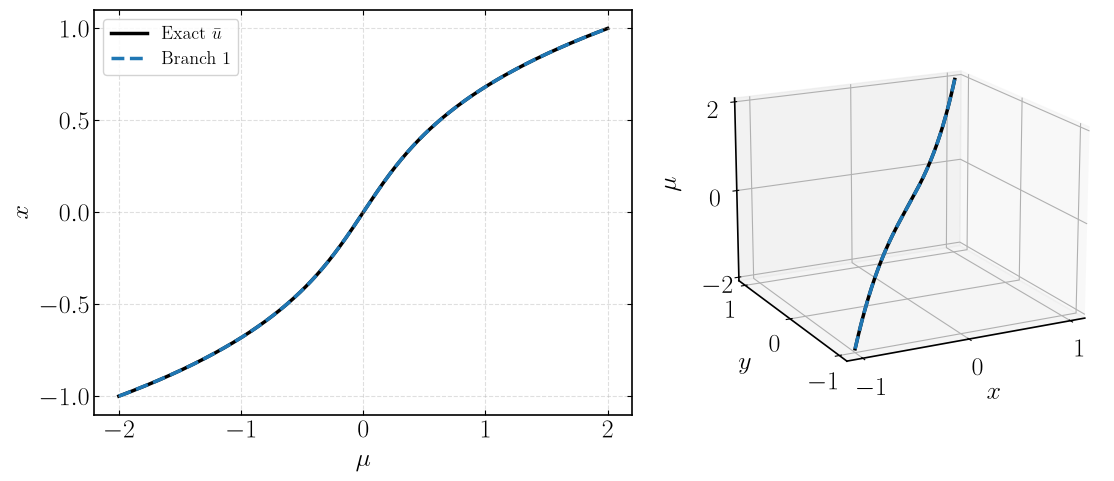

In [3]:
bounds_uq = (-2.0, 2.0)
N = 20
solver_uq = PCEGalerkin(rhs, jac, mu_bounds=bounds_uq, state_dim=2, quad_order=100)
branches_uq = solver_uq.find_branches(
    N, n_samples=10, seed=42, initialization=[[0.0, 0.0]],
)
print(f"Found {len(branches_uq)} branch(es) on {bounds_uq}")
plot_toggle(solver_uq, branches_uq)